In [92]:
# 그래프관련 import 
import matplotlib.pyplot as plt
import matplotlib
matplotlib.rcParams['font.family'] = 'Malgun Gothic'
matplotlib.rcParams['axes.unicode_minus']=False

# 프로그램 
import pandas as pd
import numpy as np
from sklearn import svm,metrics
from sklearn.neighbors import KNeighborsClassifier # 분류 클래스
from sklearn.neighbors import KNeighborsRegressor # 예측 클래스
from sklearn.linear_model import LinearRegression # 예측 클래스
from sklearn.metrics import mean_absolute_error # 평균절대오차 오차범위 클래스
from sklearn.preprocessing import StandardScaler  # 정규화 클래스
from sklearn.model_selection import train_test_split

In [93]:
perch_length = np.array(
    [8.4, 13.7, 15.0, 16.2, 17.4, 18.0, 18.7, 19.0, 19.6, 20.0,
     21.0, 21.0, 21.0, 21.3, 22.0, 22.0, 22.0, 22.0, 22.0, 22.5,
     22.5, 22.7, 23.0, 23.5, 24.0, 24.0, 24.6, 25.0, 25.6, 26.5,
     27.3, 27.5, 27.5, 27.5, 28.0, 28.7, 30.0, 32.8, 34.5, 35.0,
     36.5, 36.0, 37.0, 37.0, 39.0, 39.0, 39.0, 40.0, 40.0, 40.0,
     40.0, 42.0, 43.0, 43.0, 43.5, 44.0]
     )
perch_weight = np.array(
    [5.9, 32.0, 40.0, 51.5, 70.0, 100.0, 78.0, 80.0, 85.0, 85.0,
     110.0, 115.0, 125.0, 130.0, 120.0, 120.0, 130.0, 135.0, 110.0,
     130.0, 150.0, 145.0, 150.0, 170.0, 225.0, 145.0, 188.0, 180.0,
     197.0, 218.0, 300.0, 260.0, 265.0, 250.0, 250.0, 300.0, 320.0,
     514.0, 556.0, 840.0, 685.0, 700.0, 700.0, 690.0, 900.0, 650.0,
     820.0, 850.0, 900.0, 1015.0, 820.0, 1100.0, 1000.0, 1100.0,
     1000.0, 1000.0]
     )

In [94]:
data = np.column_stack((perch_length,perch_weight))
data[:2]

array([[ 8.4,  5.9],
       [13.7, 32. ]])

In [95]:
train_data, test_data, train_label, test_label = train_test_split(perch_length,perch_weight)
test_data

array([28. , 40. , 18.7, 24.6,  8.4, 40. , 37. , 34.5, 19.6, 27.5, 35. ,
       36. , 42. , 22.7])

In [96]:
train_data = train_data.reshape(-1,1)
test_data = test_data.reshape(-1,1)
train_data
test_data

array([[28. ],
       [40. ],
       [18.7],
       [24.6],
       [ 8.4],
       [40. ],
       [37. ],
       [34.5],
       [19.6],
       [27.5],
       [35. ],
       [36. ],
       [42. ],
       [22.7]])

In [97]:
train_poly = np.column_stack((train_data**2,train_data))
train_poly[:2]
test_poly = np.column_stack((test_data**2,test_data))
test_poly[:2]

array([[ 784.,   28.],
       [1600.,   40.]])

In [98]:
lr = LinearRegression()
lr.fit(train_poly,train_label)

predict = lr.predict(train_poly)
print('예측 무게 : ', predict)

score = lr.score(train_poly,train_label)
score2 = lr.score(test_poly,test_label)
print('train 정확도 :', score)
print('test 정확도 :', score2)


예측 무게 :  [  94.22830255  131.75292139   65.05596799  131.75292139   57.93296305
  117.66923246  271.58689609  203.70038264  153.6473374   278.01208894
 1095.77449026 1030.03058183  177.62982449  787.9356588  1030.03058183
  165.37757206  365.3742394    36.95799914  246.72135312  142.43912051
  787.9356588   142.43912051  653.59190933  318.31722573  278.01208894
  177.62982449  111.94657644  845.32728296   78.59809974  787.9356588
 1062.64152716  845.32728296  111.94657644  131.75292139   45.94206993
  131.75292139  679.41662369  478.71333524   30.61837127  131.75292139
  220.34499164  111.94657644]
train 정확도 : 0.9797319156607058
test 정확도 : 0.9446431463178041


In [99]:
print(lr.coef_,lr.intercept_)

[  1.04403553 -25.08718299] 178.35774896159677


In [100]:
print(lr.coef_[0])

1.0440355335210345


In [101]:
point = np.arange(15,50)
print(point)

[15 16 17 18 19 20 21 22 23 24 25 26 27 28 29 30 31 32 33 34 35 36 37 38
 39 40 41 42 43 44 45 46 47 48 49]


In [102]:
# 25 입력받아 산점도 그래프에 표시하고 곡선도 출력하시오 
# in_data = 25
# result = lr.predict([[in_data**2,in_data]])
# print("예측 무게 : ", result)

in_data = 1000
result = lr.predict([[in_data**2,in_data]])
print("예측 무게 : ", result)

예측 무게 :  [1019126.70827911]


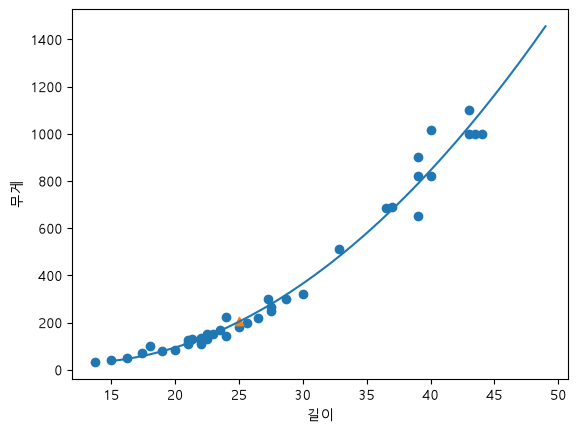

In [103]:
plt.scatter(train_data,train_label)
plt.scatter(25,208.14, marker='^')
plt.plot(point,lr.coef_[0]*point**2+lr.coef_[1]*point+lr.intercept_)
plt.xlabel('길이')
plt.ylabel('무게')
plt.show()